In [11]:
import numpy as np
import os,sys
sys.path.append(os.path.realpath('../lib'))
from graph_multimodalsentence import  graph_colors,draw_rel,draw_transp,Graph,wl_labeling,find_thresh,sp_to_adjency
from ot_distances import Fused_Gromov_Wasserstein_distance
from sentence_transformers import SentenceTransformer
from FGW import fgw_barycenters
import seaborn as sns

In [12]:
method='shortest_path_weight'
embedding = SentenceTransformer('sentence-transformers/bert-base-nli-mean-tokens')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2614.29it/s]


In [13]:
def create_graph_from_data(x,embedding):
    graphs=Graph()
    graphs.add_sentence(x,embedding)
    return graphs

In [14]:
import pandas as pd
data = pd.read_csv('../data_with_text_tag\generated_instructions_with_intention_explanation_full_ability_gender_woman_gpt.csv')

graphs=[create_graph_from_data(x,embedding) for x in data.instruction_with_intention]


Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Looking Around
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Agreeing 2
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Looking Around
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Arm Gesture (Left)
Acknowledging

In [15]:
def createbary(graphs):
    for x in graphs:
        #if x.nx_graph has no nodes of edges, remove it from the list
        if len(x.nodes())==0 or len(x.edges())==0:
            graphs.remove(x)
    Cs=[x.distance_matrix(force_recompute=True,method=method) for x in graphs]
    ps=[np.ones(len(x.nodes()))/len(x.nodes()) for x in graphs]
    Ys=[x.values() for x in graphs]
    lambdas=np.array([np.ones(len(Ys))/len(Ys)]).ravel()
    sizebary=(15,768) # we choose a barycenter with 15 nodes
    init_X=np.zeros((sizebary[0],sizebary[1]))
    D1_high,C1_high,log=fgw_barycenters(sizebary[0],Ys,Cs,ps,lambdas,alpha=0.14,init_X=init_X)
    bary_high = Graph()
    from_numpy_array(bary_high, sp_to_adjency(C1_high, threshinf=0, threshsup=find_thresh(C1_high, sup=100, step=100)[0]))
    for i in range(len(D1_high)):
        bary_high.nx_graph.add_node(i, attr_name=D1_high[i])
    return bary_high

In [16]:
def from_numpy_array(G, adj_matrix, source_node_offset=0):
        """
        Populates the graph from a numpy adjacency matrix.
        
        Args:
            adj_matrix (np.ndarray): Square matrix where adj_matrix[i, j] is the weight.
            source_node_offset (int): The starting ID for nodes. 
                                      Useful if you are adding this matrix to an existing graph.
        """
        import numpy as np
        
        rows, cols = adj_matrix.shape
        if rows != cols:
            raise ValueError("Adjacency matrix must be square.")

        # 1. Ensure all nodes exist in the graph first
        for i in range(rows):
            node_id = i + source_node_offset
            if not G.nx_graph.has_node(node_id):
                G.nx_graph.add_node(node_id)
        
        # 2. Iterate through the matrix to add edges
        # We use np.nonzero to avoid iterating over thousands of zeros in sparse matrices
        nonzero_indices = np.nonzero(adj_matrix)
        
        for i, j in zip(*nonzero_indices):
            weight = adj_matrix[i, j]
            u = i + source_node_offset
            v = j + source_node_offset
            
            # Add edge with the weight from the matrix
            # You can add additional default attributes here (e.g., type='matrix_imported')
            G.nx_graph.add_edge(u, v, weight=weight)
            
        # 3. Update the internal node counter to prevent ID collisions in future additions
        G.n_nodes = max(G.n_nodes, rows + source_node_offset)
        
        print(f"Successfully imported {len(nonzero_indices[0])} edges from matrix.")


In [17]:
def kmeans(graphs,k=3,method='shortest_path_weight',max_iter=10):
    # Initialize centroids randomly
    centroids = np.random.choice(graphs, k, replace=False)
    for i in range(max_iter):
        # Assign each graph to the nearest centroid
        clusters = {i: [] for i in range(k)}
        id_clusters = [0]*len(graphs)
        for graph in graphs:
            distances = [Fused_Gromov_Wasserstein_distance(alpha=0.14,features_metric='sqeuclidean',method=method).graph_d(graph, centroid) for centroid in centroids]
            closest_centroid = np.argmin(distances)
            clusters[closest_centroid].append(graph)
            id_clusters[graphs.index(graph)] = closest_centroid
        
        # Update centroids
        new_centroids = []
        for i in range(k):
            if clusters[i]:
                new_centroid = createbary(clusters[i])
                new_centroids.append(new_centroid)
            else:
                new_centroids.append(centroids[i])  # Keep the old centroid if no graphs are assigned
        
        
        centroids = new_centroids
    
    return clusters, centroids, id_clusters

In [21]:
data['cluster'] = id_clusters
data.head()

,instruction_id,generated_id,ability,instruction_with_intention,instruction,cluster
0,0,0_0_2,High,{f: confidence} [thoughtful] {t: Positive.Emot...,The exist sign shows left you advise to take t...,0
1,0,0_0_2,High,{f: confidence} [clear {t: Positive.Emotion} ...,The exist sign shows left you advise to take t...,0
2,0,0_0_1,Medium,{f: confidence}{g: Arm Gesture (Left)}[thought...,The exist sign shows left you advise to take t...,0
3,0,0_0_0,Low,"{f: scared} [uncertain] {t: Hedges, Negative.E...",The exist sign shows left you advise to take t...,1
4,0,0_0_0,Low,{f: confused} [short pause] {g: Arm Gesture (L...,The exist sign shows left you advise to take t...,0


<Axes: xlabel='cluster', ylabel='Count'>

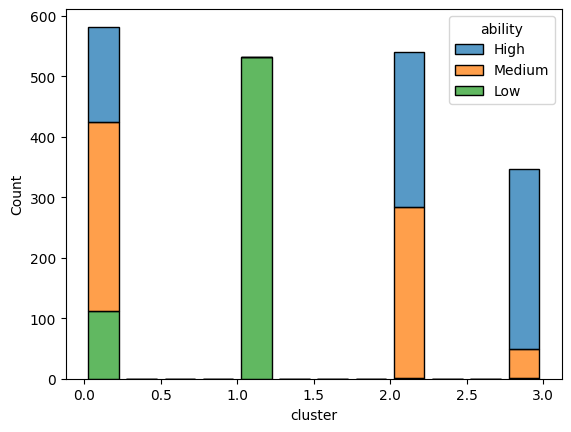

In [22]:
sns.histplot(data=data, x='cluster', hue='ability', multiple='stack', shrink=0.8)

In [23]:
def find_recurring_patterns(graphs, min_occurrences=2):
    """
    Identify recurring subgraph patterns across a list of graphs.
    
    Args:
        graphs (list): List of Graph objects to analyze.
        min_occurrences (int): Minimum number of occurrences for a pattern to be considered recurring.
        
    Returns:
        dict: A dictionary where keys are pattern identifiers and values are lists of graphs containing the pattern.
    """
    from collections import defaultdict
    
    pattern_dict = defaultdict(list)
    current_id = 0  # Initialize a counter for unique pattern identifiers
    # Iterate through each graph
    for graph in graphs:
        # Generate a unique identifier for the graph's structure (e.g., using WL labeling)
        pattern_id = current_id +1
        
        # Store the graph under its pattern identifier
        pattern_dict[pattern_id].append(graph)
        current_id += 1  # Increment the counter for the next pattern
    
    # Filter patterns based on minimum occurrences
    recurring_patterns = {pid: g_list for pid, g_list in pattern_dict.items() if len(g_list) >= min_occurrences}
    
    return recurring_patterns 

In [24]:
patterns = find_recurring_patterns(graphs, min_occurrences=2)